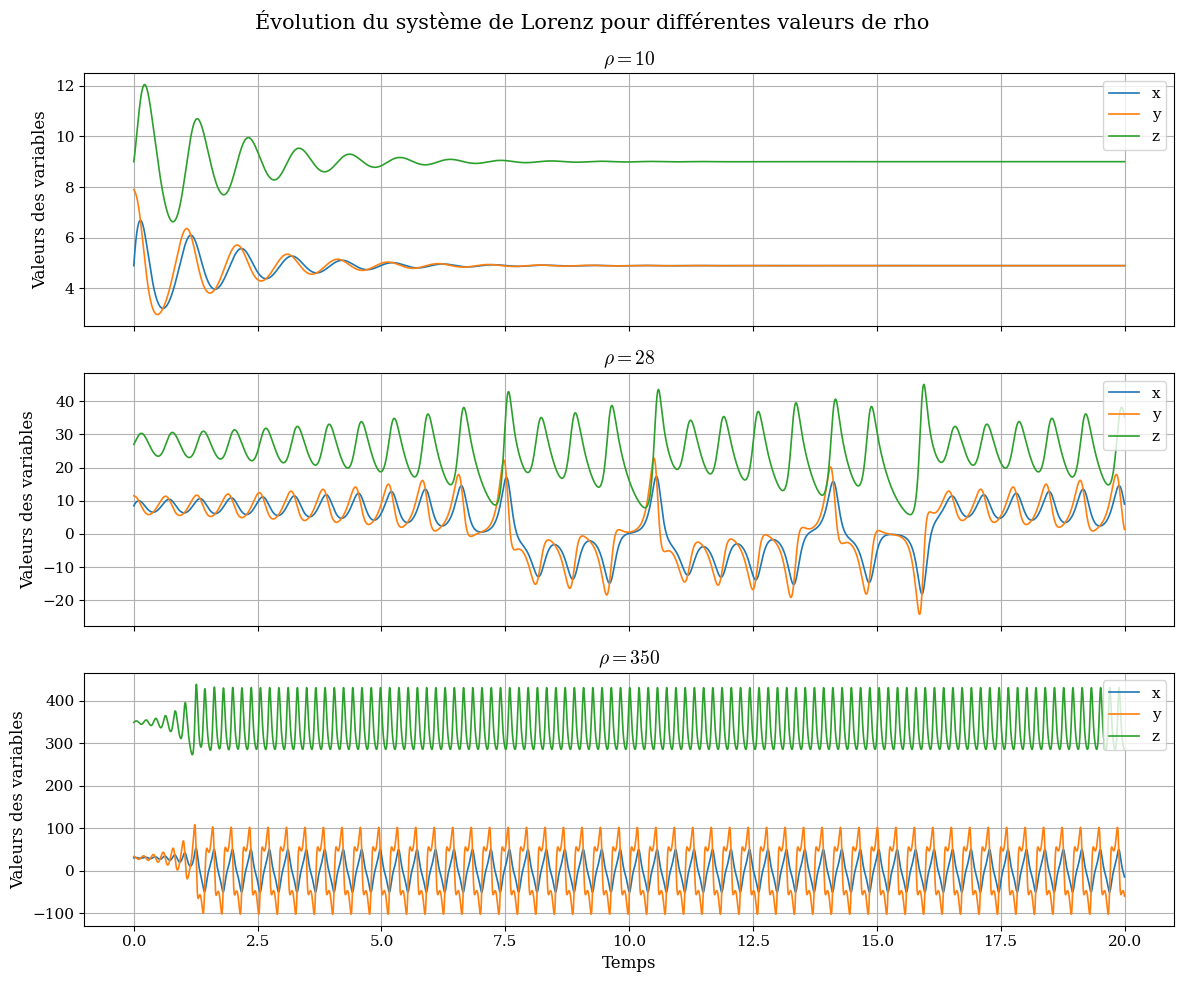

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Style proche de LaTeX
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 12,
    "mathtext.fontset": "cm"
})

# Paramètres du modèle de Lorenz
deltat = 0.001
beta = 2.667
sigma = 10
N = 2 * 10**4
rhos = [10, 28, 350]

# Création de la figure
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

for ax, rho in zip(axes, rhos):

    nu = np.sqrt(beta * (rho - 1))

    x = np.zeros(N)
    y = np.zeros(N)
    z = np.zeros(N)
    t = np.arange(N) * deltat

    # Conditions initiales
    x[0] = nu
    y[0] = nu + 3
    z[0] = rho - 1

    # Intégration Lorenz
    for i in range(N - 1):
        x[i+1] = x[i] + sigma * (y[i] - x[i]) * deltat
        y[i+1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
        z[i+1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat

    # Tracé des variables
    ax.plot(t, x, label="x", linewidth=1.2)
    ax.plot(t, y, label="y", linewidth=1.2)
    ax.plot(t, z, label="z", linewidth=1.2)

    ax.set_title(rf"$\rho = {rho}$", fontsize=14)
    ax.set_ylabel("Valeurs des variables", fontsize=12)
    ax.tick_params(axis="both", labelsize=11)
    ax.grid(True)
    ax.legend(loc="upper right", fontsize=11)

axes[-1].set_xlabel("Temps", fontsize=12)

fig.suptitle(
    "Évolution du système de Lorenz pour différentes valeurs de rho",
    fontsize=15
)

plt.tight_layout()
plt.savefig("lorenz_comparaison.png", dpi=300, bbox_inches="tight")

plt.show()

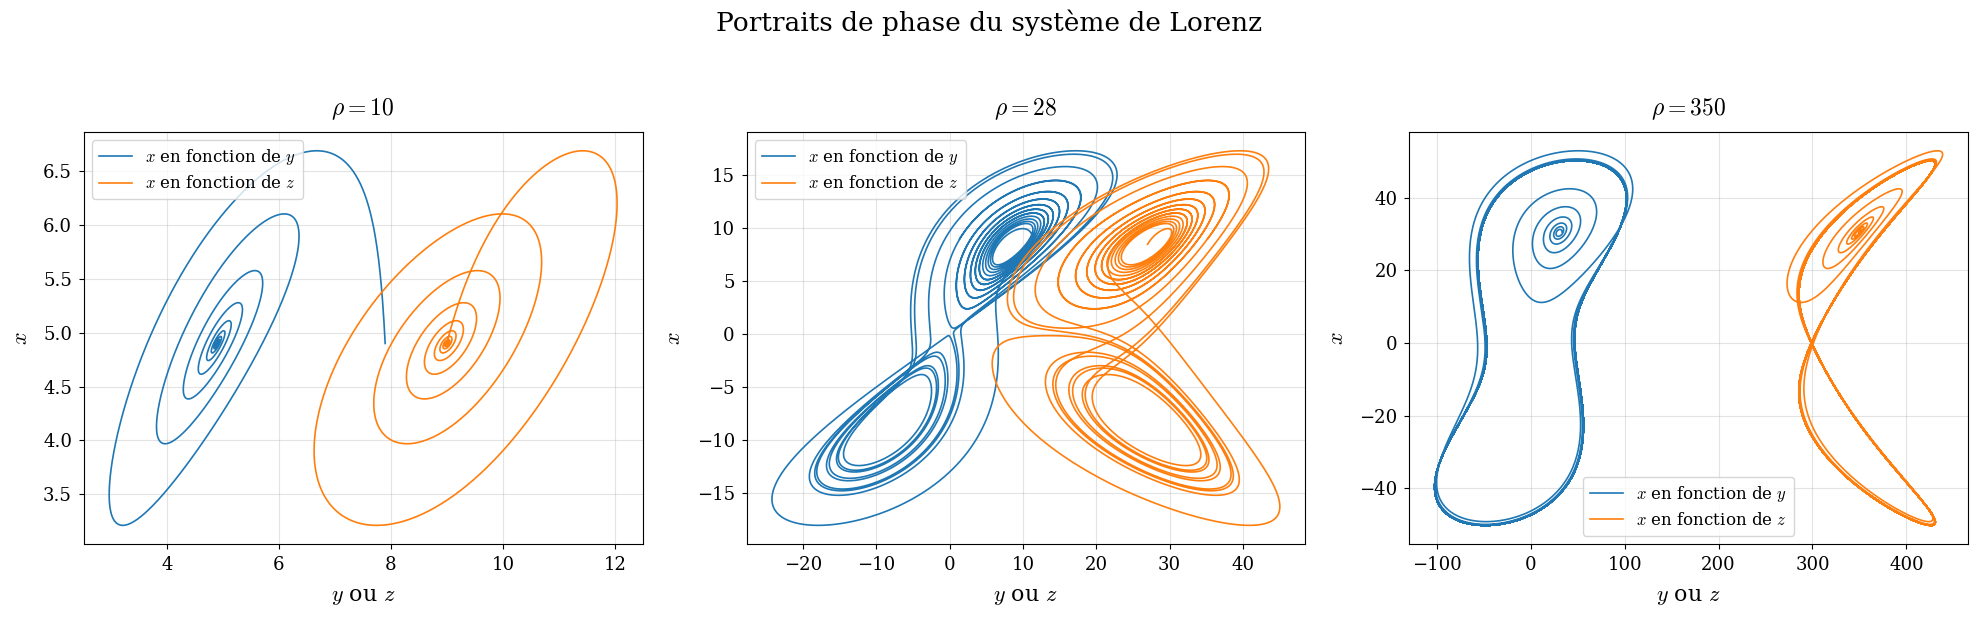

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Style proche d'un document LaTeX
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "mathtext.fontset": "cm",
    "axes.titlesize": 17,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12
})

# Paramètres
deltat = 0.001
beta = 2.667
sigma = 10
N = 2 * 10**4
rhos = [10, 28, 350]

# Figure plus grande pour améliorer la lisibilité
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, rho in zip(axes, rhos):

    nu = np.sqrt(beta * (rho - 1))

    x = np.zeros(N)
    y = np.zeros(N)
    z = np.zeros(N)

    # Conditions initiales
    x[0] = nu
    y[0] = nu + 3
    z[0] = rho - 1

    # Intégration Lorenz
    for i in range(N - 1):
        x[i+1] = x[i] + sigma * (y[i] - x[i]) * deltat
        y[i+1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
        z[i+1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat

    # Tracé des deux courbes
    ax.plot(y, x, label="$x$ en fonction de $y$", linewidth=1.2)
    ax.plot(z, x, label="$x$ en fonction de $z$", linewidth=1.2)

    ax.set_title(rf"$\rho = {rho}$", pad=12)
    ax.set_xlabel("$y$ ou $z$", labelpad=8)
    ax.set_ylabel("$x$", labelpad=8)
    ax.tick_params(axis="both", labelsize=13, pad=5)
    ax.legend(loc="best", frameon=True)
    ax.grid(True, alpha=0.35)

fig.suptitle(
    "Portraits de phase du système de Lorenz",
    fontsize=19,
    y=1.03
)

plt.tight_layout()

plt.savefig("lorenz_superposition.png", dpi=300, bbox_inches="tight")

plt.show()

Écart-type de x : 7.8400961825719016
Écart-type de y : 8.940809559754927
Écart-type de z : 8.600872330719158
Temps de prévisibilité de x : 9.183
Temps de prévisibilité de y : 4.006
Temps de prévisibilité de z : 3.926


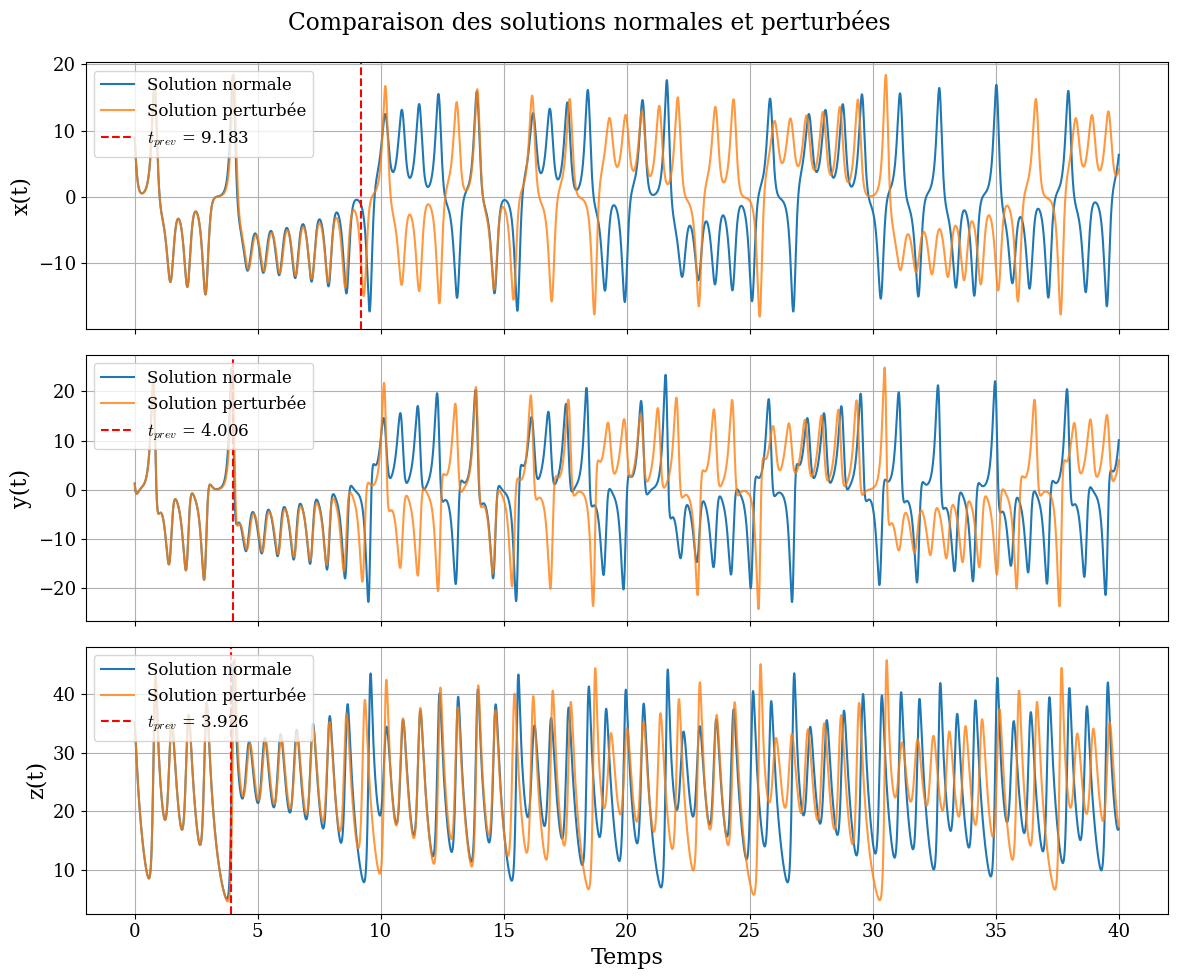

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Style proche d'un document LaTeX
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "mathtext.fontset": "cm",
    "axes.titlesize": 17,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
})

# Paramètres du modèle de Lorenz
deltat = 0.001
beta = 2.667
sigma = 10
rho = 28
N = 4 * 10**4
nu = np.sqrt(beta * (rho - 1))
perturbation = 0.01

# Création des tableaux
x = np.zeros(N)
y = np.zeros(N)
z = np.zeros(N)
t = np.zeros(N)

xpert = np.zeros(N)
ypert = np.zeros(N)
zpert = np.zeros(N)

# Conditions initiales de la solution normale
x[0] = 8.9
y[0] = 1.3
z[0] = 35.1
t[0] = 0

# Conditions initiales de la solution perturbée
xpert[0] = x[0] + perturbation
ypert[0] = y[0]
zpert[0] = z[0]

# Intégration du modèle de Lorenz par la méthode d'Euler
for i in range(N - 1):
  # Solution normale
  x[i + 1] = x[i] + sigma * (y[i] - x[i]) * deltat
  y[i + 1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
  z[i + 1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat

  # Solution perturbée
  xpert[i + 1] = xpert[i] + sigma * (ypert[i] - xpert[i]) * deltat
  ypert[i + 1] = ypert[i] + (xpert[i] * (rho - zpert[i]) - ypert[i]) * deltat
  zpert[i + 1] = zpert[i] + (xpert[i] * ypert[i] - beta * zpert[i]) * deltat

  # Temps
  t[i + 1] = (i + 1) * deltat

# ==================================================
# Calcul des moyennes
# ==================================================

moyennex = np.mean(x)
moyenney = np.mean(y)
moyennez = np.mean(z)

# ==================================================
# Calcul des écarts-types
# ==================================================

ecartx = np.sqrt(np.mean((x - moyennex) ** 2))
ecarty = np.sqrt(np.mean((y - moyenney) ** 2))
ecartz = np.sqrt(np.mean((z - moyennez) ** 2))

print("Écart-type de x :", ecartx)
print("Écart-type de y :", ecarty)
print("Écart-type de z :", ecartz)


# ==================================================
# Calcul des différences et temps de prévisibilité
# ==================================================


def temps_previsibilite(difference, ecart):
  indices = np.where(difference > ecart)[0]
  if len(indices) == 0:
    return None
  return t[indices[0]]


differencex = np.abs(x - xpert)
differencey = np.abs(y - ypert)
differencez = np.abs(z - zpert)

tempsx = temps_previsibilite(differencex, ecartx)
tempsy = temps_previsibilite(differencey, ecarty)
tempsz = temps_previsibilite(differencez, ecartz)

print("Temps de prévisibilité de x :", tempsx)
print("Temps de prévisibilité de y :", tempsy)
print("Temps de prévisibilité de z :", tempsz)

# ==================================================
# Graphiques des solutions normales et perturbées
# ==================================================

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Graphique de x
axes[0].plot(t, x, label="Solution normale")
axes[0].plot(t, xpert, label="Solution perturbée", alpha=0.8)
if tempsx is not None:
  axes[0].axvline(
      tempsx, color="red", linestyle="--", label=fr"$t_{{prev}}$ = {tempsx:.3f}"
  )
axes[0].set_ylabel("x(t)")
axes[0].legend()
axes[0].grid(True)

# Graphique de y
axes[1].plot(t, y, label="Solution normale")
axes[1].plot(t, ypert, label="Solution perturbée", alpha=0.8)
if tempsy is not None:
  axes[1].axvline(
      tempsy, color="red", linestyle="--", label=fr"$t_{{prev}}$ = {tempsy:.3f}"
  )
axes[1].set_ylabel("y(t)")
axes[1].legend()
axes[1].grid(True)

# Graphique de z
axes[2].plot(t, z, label="Solution normale")
axes[2].plot(t, zpert, label="Solution perturbée", alpha=0.8)
if tempsz is not None:
  axes[2].axvline(
      tempsz, color="red", linestyle="--", label=fr"$t_{{prev}}$ = {tempsz:.3f}"
  )
axes[2].set_ylabel("z(t)")
axes[2].set_xlabel("Temps")
axes[2].legend()
axes[2].grid(True)

fig.suptitle("Comparaison des solutions normales et perturbées")
plt.tight_layout()
plt.savefig("normale_perturbé_tprev.png", dpi=300, bbox_inches="tight")
plt.show()

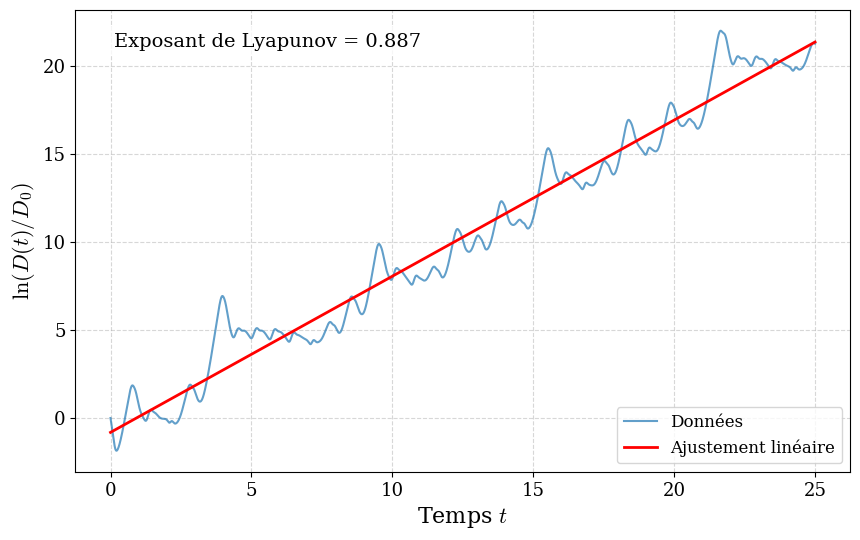

Le temps de doublement est de : 0.7814939799814196


In [21]:
import matplotlib.pyplot as plt
import numpy as np

# Style proche d'un document LaTeX
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 14,
    "mathtext.fontset": "cm",
    "axes.titlesize": 17,
    "axes.labelsize": 16,
    "xtick.labelsize": 13,
    "ytick.labelsize": 13,
    "legend.fontsize": 12,
})

# Conditions initiales
deltat = 0.001
beta = 2.667
sigma = 10
rho = 28
N = int(2.5 * 10**4)
nu = np.sqrt(beta * (rho - 1))

Distance0 = 10 ** (-8)
perturbation = Distance0

x = np.zeros(N)
y = np.zeros(N)
z = np.zeros(N)
t = np.zeros(N)

xpert = np.zeros(N)
ypert = np.zeros(N)
zpert = np.zeros(N)

x[0] = 8.9
y[0] = 1.3
z[0] = 35.1
t[0] = 0

xpert[0] = x[0] + perturbation
ypert[0] = y[0]
zpert[0] = z[0]

# Définition contrôle et perturbée
for i in range(N - 1):
  x[i + 1] = (sigma * (y[i] - x[i])) * deltat + x[i]
  y[i + 1] = (x[i] * (rho - z[i]) - y[i]) * deltat + y[i]
  z[i + 1] = (x[i] * y[i] - beta * z[i]) * deltat + z[i]
  t[i + 1] = deltat * (i + 1)
  xpert[i + 1] = (sigma * (ypert[i] - xpert[i])) * deltat + xpert[i]
  ypert[i + 1] = (xpert[i] * (rho - zpert[i]) - ypert[i]) * deltat + ypert[i]
  zpert[i + 1] = (xpert[i] * ypert[i] - beta * zpert[i]) * deltat + zpert[i]

DistanceDelta = np.sqrt(
    (xpert - x) ** 2 + (ypert - y) ** 2 + (zpert - z) ** 2
)
ln = np.log(DistanceDelta / Distance0)

pente, ordonnee = np.polyfit(t, ln, 1)
y_fit = pente * t + ordonnee

# Tracé
plt.figure(figsize=(10, 6))

plt.plot(t, ln, label="Données", alpha=0.7)
plt.plot(t, y_fit, color="red", lw=2, label="Ajustement linéaire")

# Afficher la pente sur le graphique
plt.text(
    0.05,
    0.95,
    f"Exposant de Lyapunov = {pente:.3f}",
    transform=plt.gca().transAxes,
    verticalalignment="top",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"),
)

plt.xlabel("Temps $t$")
plt.ylabel(r"$\ln(D(t)/D_0)$")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig("Lyapunov.png", dpi=300, bbox_inches="tight")
plt.show()

TD = np.log(2) / pente
print("Le temps de doublement est de :", TD)

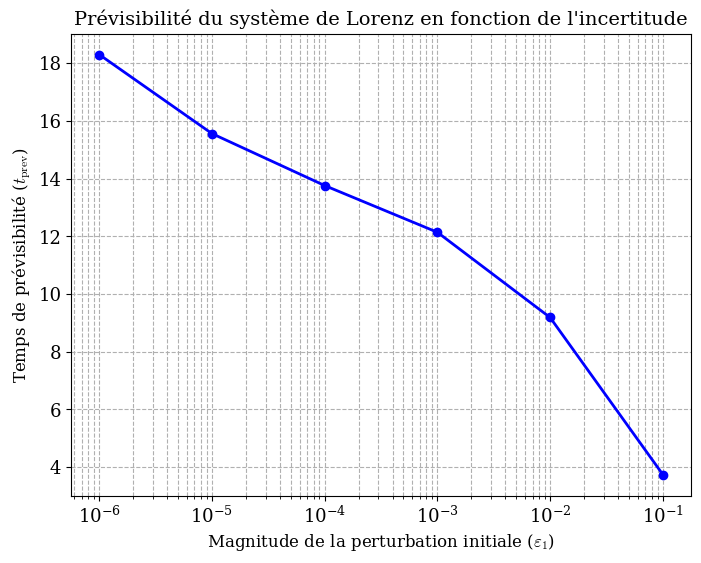

In [22]:
import matplotlib.pyplot as plt
import numpy as np

# ==================================================
# Paramètres du modèle de Lorenz
# ==================================================
deltat = 0.001
beta = 2.667
sigma = 10
rho = 28
N = 4 * 10**4

# Conditions initiales de la solution normale
x0, y0, z0 = 8.9, 1.3, 35.1

# Création du tableau de temps et de la solution normale de référence
t = np.arange(N) * deltat
x = np.zeros(N)
y = np.zeros(N)
z = np.zeros(N)

x[0] = x0
y[0] = y0
z[0] = z0

# Intégration de la solution normale (Euler)
for i in range(N - 1):
  x[i + 1] = x[i] + sigma * (y[i] - x[i]) * deltat
  y[i + 1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
  z[i + 1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat

# ==================================================
# Calcul de l'écart-type de référence pour x
# ==================================================
moyennex = np.mean(x)
ecartx = np.sqrt(np.mean((x - moyennex) ** 2))

# ==================================================
# Calcul des temps de prévisibilité pour chaque perturbation
# ==================================================
perturbations = [10**-6, 10**-5, 10**-4, 10**-3, 10**-2, 10**-1]
temps_prevs = []


def temps_previsibilite(difference, ecart, t_arr):
  indices = np.where(difference > ecart)[0]
  if len(indices) == 0:
    return None
  return t_arr[indices[0]]


for p in perturbations:
  xpert = np.zeros(N)
  ypert = np.zeros(N)
  zpert = np.zeros(N)

  xpert[0] = x[0] + p
  ypert[0] = y[0]
  zpert[0] = z[0]

  # solution perturbée
  for i in range(N - 1):
    xpert[i + 1] = xpert[i] + sigma * (ypert[i] - xpert[i]) * deltat
    ypert[i + 1] = ypert[i] + (xpert[i] * (rho - zpert[i]) - ypert[i]) * deltat
    zpert[i + 1] = zpert[i] + (xpert[i] * ypert[i] - beta * zpert[i]) * deltat

  differencex = np.abs(x - xpert)
  tp = temps_previsibilite(differencex, ecartx, t)
  temps_prevs.append(tp)

# Tracé du graphique

plt.figure(figsize=(8, 6))
plt.plot(
    perturbations,
    temps_prevs,
    marker="o",
    linestyle="-",
    color="b",
    linewidth=2,
)
plt.xscale("log")
plt.xlabel(
    r"Magnitude de la perturbation initiale ($\varepsilon_1$)", fontsize=12
)
plt.ylabel(r"Temps de prévisibilité ($t_{\text{prev}}$)", fontsize=12)
plt.title(
    "Prévisibilité du système de Lorenz en fonction de l'incertitude",
    fontsize=14,
)
plt.grid(True, which="both", ls="--")
plt.savefig("previsibilite_vs_perturbation.png", dpi=300, bbox_inches="tight")
plt.show()

CI A : t_prev = 1.829
CI B : t_prev = 2.174
CI C : t_prev = 4.285
CI D : t_prev = 7.060
CI E : t_prev = 8.840
CI F : t_prev = 9.618


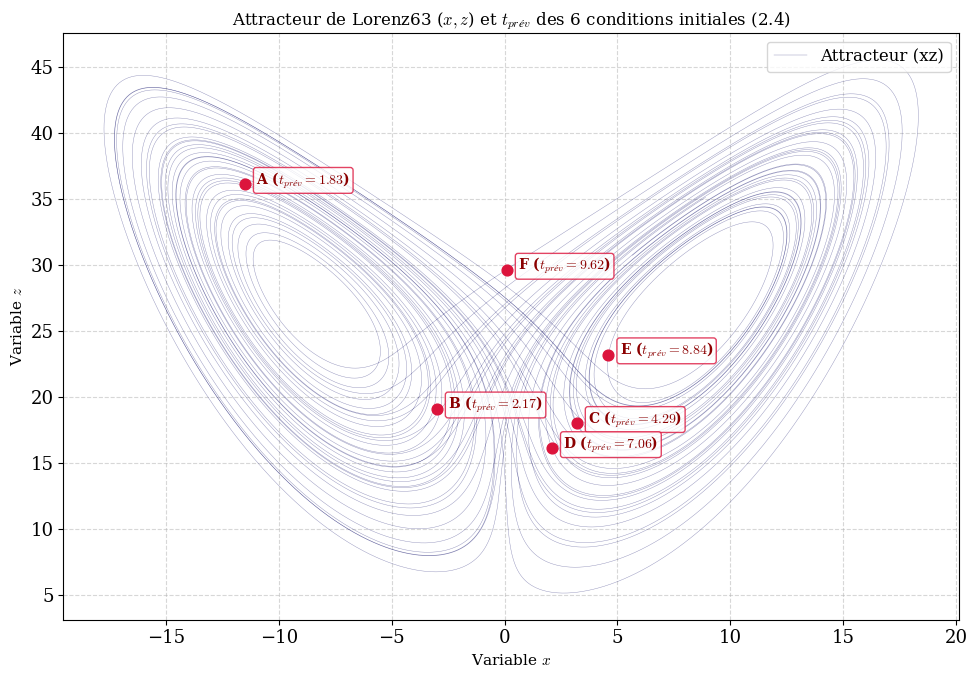

In [23]:
import matplotlib.pyplot as plt
import numpy as np

# Paramètres
sigma = 10.0
rho = 28.0
beta = 2.667
deltat = 0.001
N = 40000
epsilon = 0.01

lettres = ['A', 'B', 'C', 'D', 'E', 'F']

CI = np.array([
    [-11.5, -6.0, 36.1],
    [-3.0, -4.8, 19.1],
    [3.2, 4.2, 18.0],
    [2.1, 3.0, 16.1],
    [4.6, 6.9, 23.2],
    [0.1, 7.1, 29.6],
])

temps_prev = []

# 1. Calcul de t_prev
for j in range(len(CI)):
  x = np.zeros(N)
  y = np.zeros(N)
  z = np.zeros(N)

  xp = np.zeros(N)
  yp = np.zeros(N)
  zp = np.zeros(N)

  x[0], y[0], z[0] = CI[j]
  xp[0] = x[0] + epsilon
  yp[0] = y[0]
  zp[0] = z[0]

  for i in range(N - 1):
    x[i + 1] = x[i] + sigma * (y[i] - x[i]) * deltat
    y[i + 1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
    z[i + 1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat

    xp[i + 1] = xp[i] + sigma * (yp[i] - xp[i]) * deltat
    yp[i + 1] = yp[i] + (xp[i] * (rho - zp[i]) - yp[i]) * deltat
    zp[i + 1] = zp[i] + (xp[i] * yp[i] - beta * zp[i]) * deltat

  ecartx = np.std(x)
  differencex = np.abs(x - xp)

  # Correction : extraction du tableau d'indices avec [0]
  indices = np.where(differencex > ecartx)[0]

  if len(indices) > 0:
    tprev = indices[0] * deltat  # On prend le premier instant de divergence
  else:
    tprev = np.nan

  temps_prev.append(tprev)
  print(f'CI {lettres[j]} : t_prev = {tprev:.3f}')

# 2. Génération d'une longue simulation pour tracer l'attracteur en arrière-plan
N_long = 50000
x_att, y_att, z_att = np.zeros(N_long), np.zeros(N_long), np.zeros(N_long)
x_att[0], y_att[0], z_att[0] = 8.9, 1.3, 35.1

for i in range(N_long - 1):
  x_att[i + 1] = x_att[i] + sigma * (y_att[i] - x_att[i]) * deltat
  y_att[i + 1] = (
      y_att[i] + (x_att[i] * (rho - z_att[i]) - y_att[i]) * deltat
  )
  z_att[i + 1] = (
      z_att[i] + (x_att[i] * y_att[i] - beta * z_att[i]) * deltat
  )

# 3. Tracé graphique
plt.figure(figsize=(10, 7))

# Tracé de l'attracteur
plt.plot(
    x_att,
    z_att,
    color='midnightblue',
    lw=0.3,
    alpha=0.5,
    label='Attracteur (xz)',
)

# Superposition des 6 points et affichage de leur t_prev
for j in range(len(CI)):
  pt_x = CI[j][0]
  pt_z = CI[j][2]
  tp = temps_prev[j]

  # Affichage du point sur l'attracteur
  plt.scatter(pt_x, pt_z, color='crimson', s=60, zorder=5)

  # Étiquette textuelle avec la lettre et le temps de prévisibilité
  plt.text(
      pt_x + 0.5,
      pt_z,
      f'{lettres[j]} ($t_{{prév}}={tp:.2f}$)',
      fontsize=10,
      fontweight='bold',
      color='darkred',
      bbox=dict(
          boxstyle='round,pad=0.2',
          facecolor='white',
          edgecolor='crimson',
          alpha=0.8,
      ),
  )

plt.title(
    'Attracteur de Lorenz63 ($x, z$) et $t_{prév}$ des 6 conditions initiales'
    ' (2.4)',
    fontsize=12,
)
plt.xlabel('Variable $x$', fontsize=11)
plt.ylabel('Variable $z$', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()

plt.show()

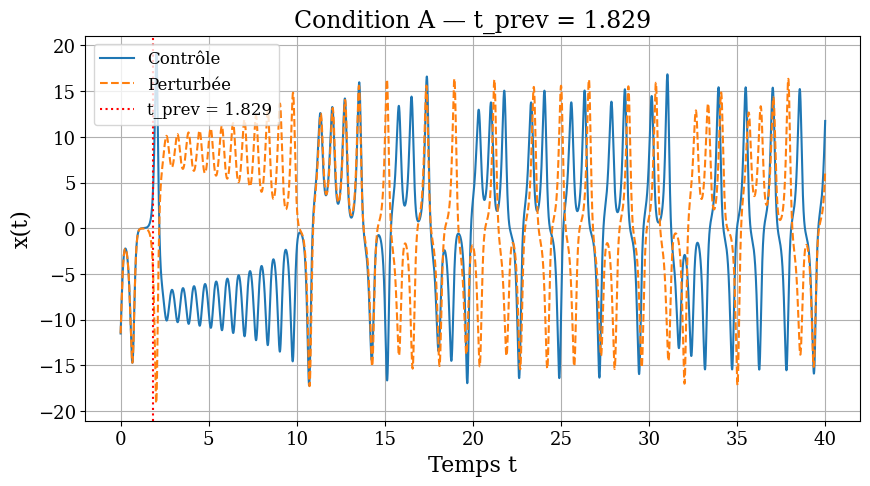

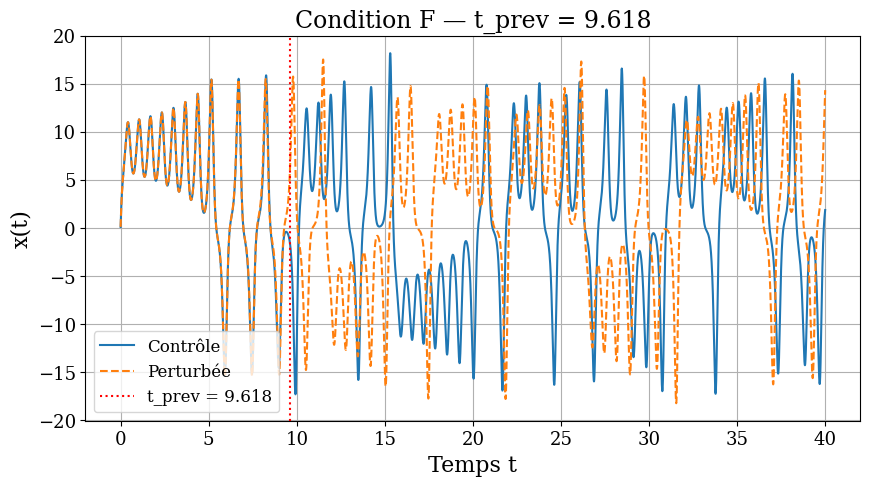

In [24]:
# Tracer les trajectoires de contrôle et perturbée
def tracer_trajectoires(j):
    x = np.zeros(N)
    y = np.zeros(N)
    z = np.zeros(N)

    xp = np.zeros(N)
    yp = np.zeros(N)
    zp = np.zeros(N)

    # Conditions initiales
    x[0], y[0], z[0] = CI[j]
    xp[0] = x[0] + epsilon
    yp[0] = y[0]
    zp[0] = z[0]

    # Intégration du modèle de Lorenz
    for i in range(N - 1):
        x[i+1] = x[i] + sigma*(y[i]-x[i])*deltat
        y[i+1] = y[i] + (x[i]*(rho-z[i])-y[i])*deltat
        z[i+1] = z[i] + (x[i]*y[i]-beta*z[i])*deltat

        xp[i+1] = xp[i] + sigma*(yp[i]-xp[i])*deltat
        yp[i+1] = yp[i] + (xp[i]*(rho-zp[i])-yp[i])*deltat
        zp[i+1] = zp[i] + (xp[i]*yp[i]-beta*zp[i])*deltat

    t = np.arange(N) * deltat

    plt.figure(figsize=(10, 5))
    plt.plot(t, x, label="Contrôle")
    plt.plot(t, xp, "--", label="Perturbée")
    plt.axvline(temps_prev[j], color="red", linestyle=":",
                label=f"t_prev = {temps_prev[j]:.3f}")

    plt.xlabel("Temps t")
    plt.ylabel("x(t)")
    plt.title(f"Condition {lettres[j]} — t_prev = {temps_prev[j]:.3f}")
    plt.legend()
    plt.grid(True)
    plt.show()

indice_min = np.nanargmin(temps_prev)
indice_max = np.nanargmax(temps_prev)


tracer_trajectoires(indice_min)
tracer_trajectoires(indice_max)

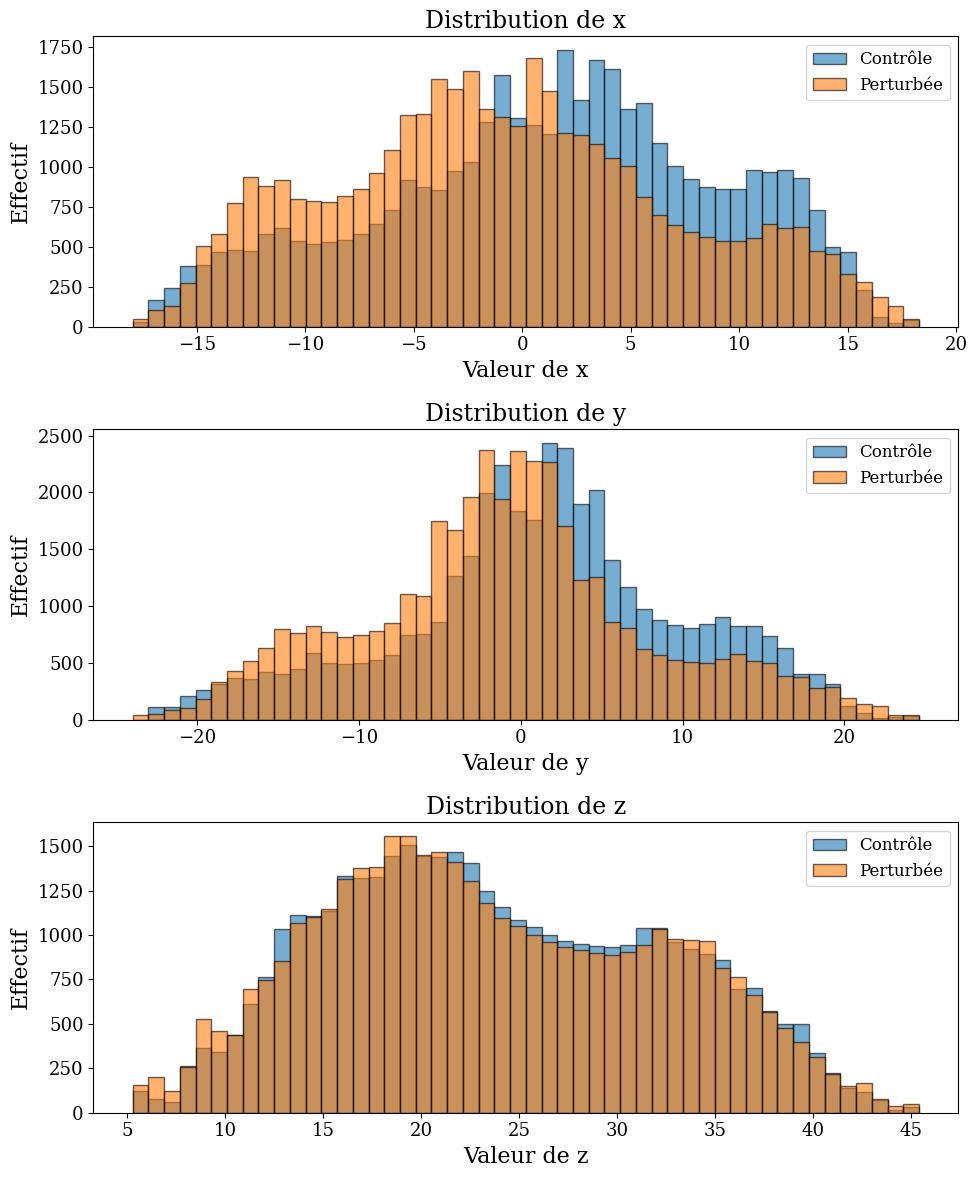

In [25]:
import numpy as np
import matplotlib.pyplot as plt

# 3 histogrammes
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

# Histogramme de x
limites_x = np.linspace(
    min(x.min(), xpert.min()),
    max(x.max(), xpert.max()),
    51
)

axes[0].hist(x, bins=limites_x, alpha=0.6,
             label="Contrôle", edgecolor="black")
axes[0].hist(xpert, bins=limites_x, alpha=0.6,
             label="Perturbée", edgecolor="black")

axes[0].set_xlabel("Valeur de x")
axes[0].set_ylabel("Effectif")
axes[0].set_title("Distribution de x")
axes[0].legend()

# Histogramme de y
limites_y = np.linspace(
    min(y.min(), ypert.min()),
    max(y.max(), ypert.max()),
    51
)

axes[1].hist(y, bins=limites_y, alpha=0.6,
             label="Contrôle", edgecolor="black")
axes[1].hist(ypert, bins=limites_y, alpha=0.6,
             label="Perturbée", edgecolor="black")

axes[1].set_xlabel("Valeur de y")
axes[1].set_ylabel("Effectif")
axes[1].set_title("Distribution de y")
axes[1].legend()


# Histogramme de z

limites_z = np.linspace(
    min(z.min(), zpert.min()),
    max(z.max(), zpert.max()),
    51
)

axes[2].hist(z, bins=limites_z, alpha=0.6,
             label="Contrôle", edgecolor="black")
axes[2].hist(zpert, bins=limites_z, alpha=0.6,
             label="Perturbée", edgecolor="black")

axes[2].set_xlabel("Valeur de z")
axes[2].set_ylabel("Effectif")
axes[2].set_title("Distribution de z")
axes[2].legend()
plt.tight_layout()
plt.savefig("histogrammes_distribution", dpi=300, bbox_inches='tight')
plt.show()

In [26]:
from scipy import stats
import numpy as np

# Dictionnaire regroupant vos variables
variables = {
    "X": (x, xpert),
    "Y": (y, ypert),
    "Z": (z, zpert)
}

print("=== RAPPORT D'ANALYSE STATISTIQUE ===\n")

for nom, (controle, perturbe) in variables.items():
    # 1. Test de Kolmogorov-Smirnov (compare les distributions globales)
    ks_res = stats.ks_2samp(controle, perturbe)
    
    print(f"--- Variable {nom} ---")
    print(f"  • Test K-S   : p-value = {ks_res.pvalue:.4e} (D = {ks_res.statistic:.4f})")
    
    if ks_res.pvalue < 0.05:
        print(f"  Résultat : La perturbation a un impact **significatif** sur la distribution de {nom}.\n")
    else:
        print(f"  Résultat : Pas de différence statistiquement significative détectée pour {nom}.\n")

=== RAPPORT D'ANALYSE STATISTIQUE ===

--- Variable X ---
  • Test K-S   : p-value = 0.0000e+00 (D = 0.1619)
  Résultat : La perturbation a un impact **significatif** sur la distribution de X.

--- Variable Y ---
  • Test K-S   : p-value = 0.0000e+00 (D = 0.1565)
  Résultat : La perturbation a un impact **significatif** sur la distribution de Y.

--- Variable Z ---
  • Test K-S   : p-value = 1.4338e-05 (D = 0.0172)
  Résultat : La perturbation a un impact **significatif** sur la distribution de Z.



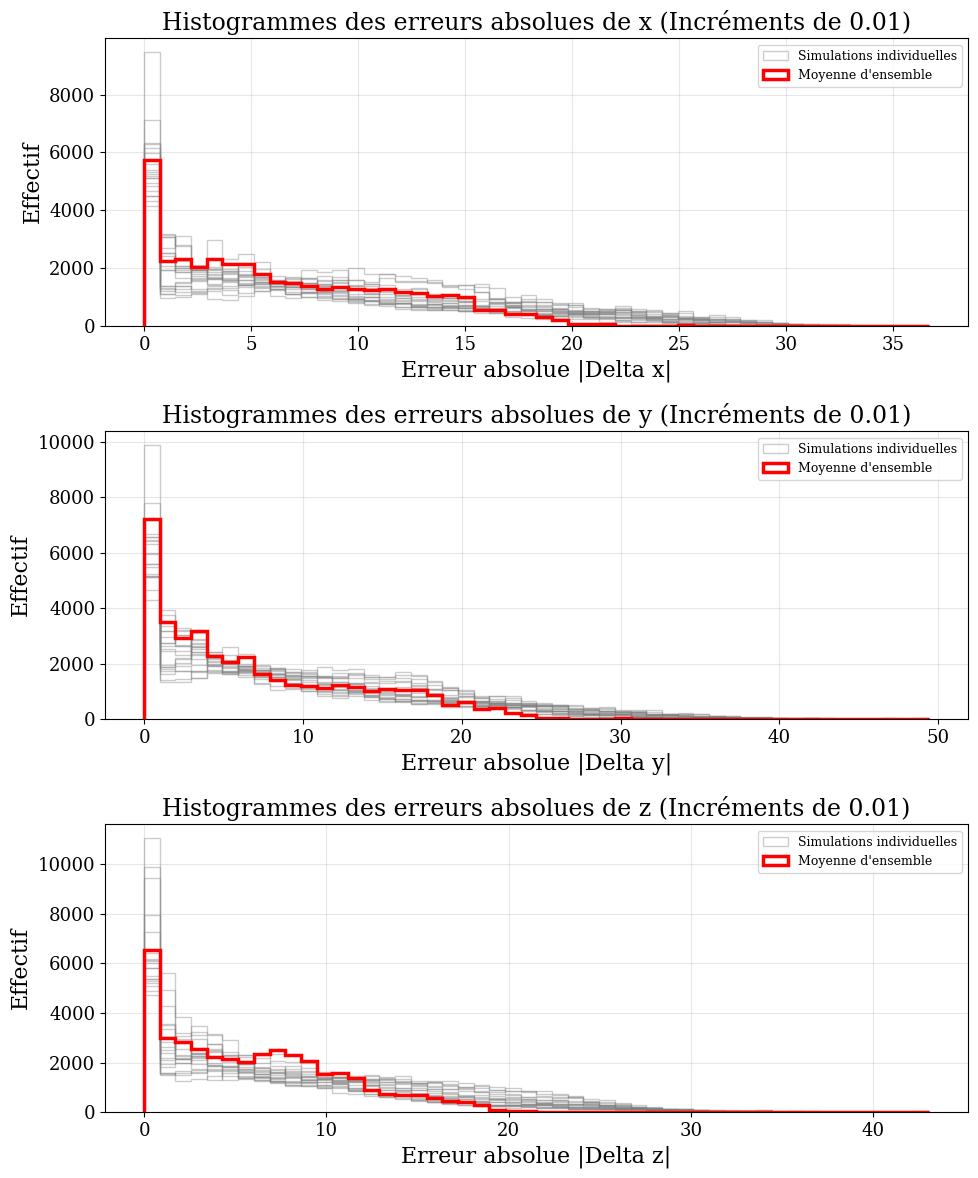

In [29]:
import numpy as np
import matplotlib.pyplot as plt


# 1. Paramètres
deltat = 0.001
beta = 2.667
sigma = 10
rho = 28
N = 4 * 10**4
t = np.arange(N) * deltat

x0 = 8.9
y0 = 1.3
z0 = 35.1


# 2. Simulation de contrôle

x = np.zeros(N)
y = np.zeros(N)
z = np.zeros(N)
x[0], y[0], z[0] = x0, y0, z0

for i in range(N - 1):
    x[i+1] = x[i] + sigma * (y[i] - x[i]) * deltat
    y[i+1] = y[i] + (x[i] * (rho - z[i]) - y[i]) * deltat
    z[i+1] = z[i] + (x[i] * y[i] - beta * z[i]) * deltat


# 3. Simulations avec erreurs progressives

num_simulations = 20
epsilon_init = 0.01 
pas = 0.01           

x_pert_all = np.zeros((num_simulations, N))
y_pert_all = np.zeros((num_simulations, N))
z_pert_all = np.zeros((num_simulations, N))

for sim in range(num_simulations):
    eps = epsilon_init + sim * pas
    
    xpert = np.zeros(N)
    ypert = np.zeros(N)
    zpert = np.zeros(N)

    xpert[0] = x0 + eps
    ypert[0] = y0
    zpert[0] = z0

    for i in range(N - 1):
        xpert[i+1] = xpert[i] + sigma * (ypert[i] - xpert[i]) * deltat
        ypert[i+1] = ypert[i] + (xpert[i] * (rho - zpert[i]) - ypert[i]) * deltat
        zpert[i+1] = zpert[i] + (xpert[i] * ypert[i] - beta * zpert[i]) * deltat

    x_pert_all[sim] = xpert
    y_pert_all[sim] = ypert
    z_pert_all[sim] = zpert


# 4. Calcul de la moyenne d'ensemble

x_ensemble_mean = np.mean(x_pert_all, axis=0)
y_ensemble_mean = np.mean(y_pert_all, axis=0)
z_ensemble_mean = np.mean(z_pert_all, axis=0)


# 5. Calcul des erreurs absolues

abs_diff_x_all = np.abs(x_pert_all - x)
abs_diff_y_all = np.abs(y_pert_all - y)
abs_diff_z_all = np.abs(z_pert_all - z)

abs_diff_x_mean = np.abs(x_ensemble_mean - x)
abs_diff_y_mean = np.abs(y_ensemble_mean - y)
abs_diff_z_mean = np.abs(z_ensemble_mean - z)


# 6. Tracé des histogrammes d'erreurs absolues avec bins partagés

fig, axes = plt.subplots(3, 1, figsize=(10, 12))


bins_x = np.linspace(0, max(np.max(abs_diff_x_all), np.max(abs_diff_x_mean)), 51)
bins_y = np.linspace(0, max(np.max(abs_diff_y_all), np.max(abs_diff_y_mean)), 51)
bins_z = np.linspace(0, max(np.max(abs_diff_z_all), np.max(abs_diff_z_mean)), 51)

# Tracé des histogrammes individuels pour chaque simulation
for sim in range(num_simulations):
    label_text = "Simulations individuelles" if sim == 0 else ""
    
    axes[0].hist(abs_diff_x_all[sim], bins=bins_x, histtype='step', alpha=0.4, color='gray', linewidth=1, label=label_text)
    axes[1].hist(abs_diff_y_all[sim], bins=bins_y, histtype='step', alpha=0.4, color='gray', linewidth=1, label=label_text)
    axes[2].hist(abs_diff_z_all[sim], bins=bins_z, histtype='step', alpha=0.4, color='gray', linewidth=1, label=label_text)

# Tracé de l'histogramme de la moyenne d'ensemble en surbrillance (rouge)
axes[0].hist(abs_diff_x_mean, bins=bins_x, histtype='step', color='red', linewidth=2.5, label="Moyenne d'ensemble")
axes[1].hist(abs_diff_y_mean, bins=bins_y, histtype='step', color='red', linewidth=2.5, label="Moyenne d'ensemble")
axes[2].hist(abs_diff_z_mean, bins=bins_z, histtype='step', color='red', linewidth=2.5, label="Moyenne d'ensemble")


# 7. Mise en forme des graphiques

axes[0].set_xlabel("Erreur absolue |Delta x|")
axes[0].set_ylabel("Effectif")
axes[0].set_title("Histogrammes des erreurs absolues de x (Incréments de 0.01)")
axes[0].legend(loc="upper right", fontsize=9)
axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel("Erreur absolue |Delta y|")
axes[1].set_ylabel("Effectif")
axes[1].set_title("Histogrammes des erreurs absolues de y (Incréments de 0.01)")
axes[1].legend(loc="upper right", fontsize=9)
axes[1].grid(True, alpha=0.3)

axes[2].set_xlabel("Erreur absolue |Delta z|")
axes[2].set_ylabel("Effectif")
axes[2].set_title("Histogrammes des erreurs absolues de z (Incréments de 0.01)")
axes[2].legend(loc="upper right", fontsize=9)
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("histogrammes_erreurs_absolues_propre_lorenz.png", dpi=300, bbox_inches='tight')
plt.show()